# BeatBridge: Batch anhören

Dieses Notebook lädt einen Batch über sein `manifest.json`, richtet die Waveforms beider Songs an ihren Cue Points aus, visualisiert die Render-Metriken, zeigt die gerenderten Varianten und spielt sie direkt im Notebook ab. Es setzt keine zusätzlichen Widgets voraus.

Starten Sie Jupyter im Projekt-Root (`BeatBridge`) und führen Sie die Zellen von oben nach unten aus. Für einen anderen Batch nur `BATCH_DIR` in der nächsten Zelle ändern.

In [1]:
from pathlib import Path
import json
import sys

import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, Markdown, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.ratings import ISSUE_TAGS, rating_summary, save_rating

# Für einen anderen Lauf diesen Paar-Ordner anpassen.
BATCH_DIR = (
    PROJECT_ROOT
    / "output"
    / "batches"
    / "all_songs_top3_targets_top3_transitions_20260722"
    / "pairs"
    / "05__05_HELP_LESS__target-02__07_BREATH_LESS"
)
MANIFEST_PATH = BATCH_DIR / "manifest.json"

if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest nicht gefunden: {MANIFEST_PATH.resolve()}")

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
metrics_path = BATCH_DIR / "transition_metrics.json"
metric_scores = manifest.get("rendered_transition_ranking", {}).get("scores", [])
if metrics_path.is_file() and not metric_scores:
    historical_metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    metric_scores = historical_metrics.get("ranking", {}).get("scores", [])
    metric_variants = {
        (item["candidate_id"], item["renderer"]): item
        for item in historical_metrics["variants"]
    }
    for item in manifest["rendered_variants"]:
        metric = metric_variants.get((item["candidate_id"], item["renderer"]))
        if metric is not None:
            item.update(
                transition_rank=metric.get("transition_rank"),
                transition_score=metric.get("transition_score"),
            )
metric_score_by_variant = {
    (item["candidate_id"], item["renderer"]): item
    for item in metric_scores
}
variants = sorted(
    manifest["rendered_variants"],
    key=lambda item: (
        item.get("transition_rank") or item.get("candidate_rank") or 10**9,
        item["renderer"],
    ),
)
candidates = {item["candidate_id"]: item for item in manifest["candidate_generation"]["candidates"]}

def display_score(variant, key):
    score = variant.get(key)
    return "?" if score is None else f"{score:.3f}"

print(f"{len(candidates)} Kandidat(en), {len(variants)} gerenderte Variante(n)")
print(f"Renderer: {', '.join(manifest['renderers'])}")
print(f"Render-Metriken: {len(metric_score_by_variant)} Variante(n)")

14196 Kandidat(en), 3 gerenderte Variante(n)
Renderer: equal_power
Render-Metriken: 3 Variante(n)


In [2]:
for index, variant in enumerate(variants):
    candidate = candidates[variant["candidate_id"]]
    print(
        f"[{index}] Render-Rang {variant.get('transition_rank', '?')} / "
        f"Render-Score {display_score(variant, 'transition_score')} / "
        f"Cutpoint-Rang {variant.get('candidate_rank', '?')} / "
        f"Cutpoint-Score {display_score(variant, 'candidate_score')} / "
        f"{variant['renderer']}: "
        f"{candidate['transition_length_bars']} Takte / "
        f"{candidate['transition_length_beats']} Beats — "
        f"{variant['output_file']}"
    )

[0] Render-Rang 1 / Render-Score 0.838 / Cutpoint-Rang 2 / Cutpoint-Score 0.749 / equal_power: 4 Takte / 16 Beats — rendered\0002__candidate-2801340071d831d4__equal_power.wav
[1] Render-Rang 2 / Render-Score 0.805 / Cutpoint-Rang 1 / Cutpoint-Score 0.751 / equal_power: 4 Takte / 16 Beats — rendered\0001__candidate-5f8a2a500211a427__equal_power.wav
[2] Render-Rang 3 / Render-Score 0.779 / Cutpoint-Rang 3 / Cutpoint-Score 0.746 / equal_power: 4 Takte / 16 Beats — rendered\0003__candidate-56c83536e071300f__equal_power.wav


## Metrikübersicht

Links ist die Verteilung der Render-Scores zu sehen. Liegt der gewählte Paar-Ordner in einem nachbewerteten Multi-Song-Batch, werden alle Varianten dieses Batches einbezogen. Rechts werden Cutpoint- und Render-Score verglichen; das aktuelle Songpaar ist hervorgehoben und mit den Variantenindizes aus der Liste oben beschriftet.

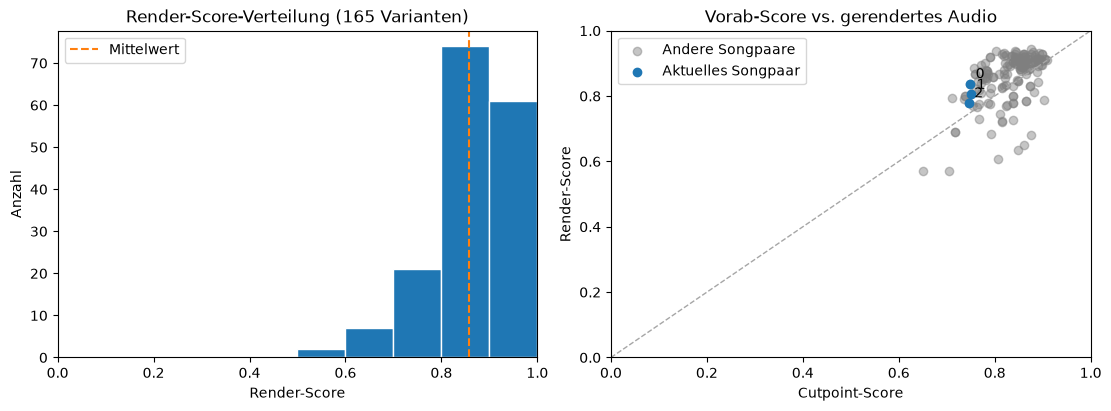

In [3]:
METRIC_LABELS = {
    "energy_shape": "Energieform",
    "boundary_smoothness": "Grenzglätte",
    "harmonic_continuity": "Harmonische Kontinuität",
    "rhythmic_stability": "Rhythmische Stabilität",
}

def metric_score_for(variant):
    return metric_score_by_variant.get((variant["candidate_id"], variant["renderer"]))

def load_overview_points():
    """Lade Metriken des umgebenden Multi-Batches oder nur des aktuellen Paars."""
    current_index_by_variant = {
        (variant["candidate_id"], variant["renderer"]): index
        for index, variant in enumerate(variants)
    }
    multi_batch_dir = BATCH_DIR.parent.parent
    if BATCH_DIR.parent.name == "pairs" and (multi_batch_dir / "transition_metrics.json").is_file():
        pair_directories = sorted(path for path in BATCH_DIR.parent.iterdir() if path.is_dir())
    else:
        pair_directories = [BATCH_DIR]

    points = []
    for pair_directory in pair_directories:
        pair_manifest_path = pair_directory / "manifest.json"
        if not pair_manifest_path.is_file():
            continue
        pair_manifest = json.loads(pair_manifest_path.read_text(encoding="utf-8"))
        pair_scores = pair_manifest.get("rendered_transition_ranking", {}).get("scores", [])
        pair_metrics_path = pair_directory / "transition_metrics.json"
        if pair_metrics_path.is_file() and not pair_scores:
            pair_metrics = json.loads(pair_metrics_path.read_text(encoding="utf-8"))
            pair_scores = pair_metrics.get("ranking", {}).get("scores", [])
        pair_variants = {
            (item["candidate_id"], item["renderer"]): item
            for item in pair_manifest.get("rendered_variants", [])
        }
        for score in pair_scores:
            key = (score["candidate_id"], score["renderer"])
            variant = pair_variants.get(key, {})
            points.append({
                "candidate_score": variant.get("candidate_score"),
                "current_index": current_index_by_variant.get(key) if pair_directory == BATCH_DIR else None,
                "is_current_pair": pair_directory == BATCH_DIR,
                "render_score": score["total_score"],
            })
    return points

def plot_batch_metric_overview():
    """Zeige Scoreverteilung und Cutpoint-vs.-Render-Vergleich für den Batch."""
    points = load_overview_points()
    if not points:
        print("Keine Render-Metriken für diesen Batch vorhanden.")
        return None

    figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    render_scores = [point["render_score"] for point in points]
    axes[0].hist(render_scores, bins=[step / 10 for step in range(11)], color="C0", edgecolor="white")
    axes[0].axvline(sum(render_scores) / len(render_scores), color="C1", linestyle="--", label="Mittelwert")
    axes[0].set(
        xlim=(0, 1),
        xlabel="Render-Score",
        ylabel="Anzahl",
        title=f"Render-Score-Verteilung ({len(points)} Varianten)",
    )
    axes[0].legend()

    paired = [point for point in points if point["candidate_score"] is not None]
    if paired:
        other_pairs = [point for point in paired if not point["is_current_pair"]]
        current_pair = [point for point in paired if point["is_current_pair"]]
        if other_pairs:
            axes[1].scatter(
                [point["candidate_score"] for point in other_pairs],
                [point["render_score"] for point in other_pairs],
                color="C7",
                alpha=0.45,
                label="Andere Songpaare",
            )
        axes[1].scatter(
            [point["candidate_score"] for point in current_pair],
            [point["render_score"] for point in current_pair],
            color="C0",
            label="Aktuelles Songpaar",
        )
        for point in current_pair:
            if point["current_index"] is not None:
                axes[1].annotate(
                    str(point["current_index"]),
                    (point["candidate_score"], point["render_score"]),
                    xytext=(4, 4),
                    textcoords="offset points",
                )
        axes[1].plot([0, 1], [0, 1], color="0.65", linestyle="--", linewidth=1)
        axes[1].set(
            xlim=(0, 1),
            ylim=(0, 1),
            xlabel="Cutpoint-Score",
            ylabel="Render-Score",
            title="Vorab-Score vs. gerendertes Audio",
        )
        axes[1].legend()
    else:
        axes[1].text(0.5, 0.5, "Keine Cutpoint-Scores vorhanden", ha="center", va="center")
        axes[1].set_axis_off()
    return figure

overview_figure = plot_batch_metric_overview()
if overview_figure is not None:
    display(overview_figure)
    plt.close(overview_figure)

### Variante 0: Render-Rang 1, Render-Score 0.838, Cutpoint-Rang 2, Cutpoint-Score 0.749, `equal_power`  
Kandidat `candidate-2801340071d831d4`, 4 Takte / 16 Beats

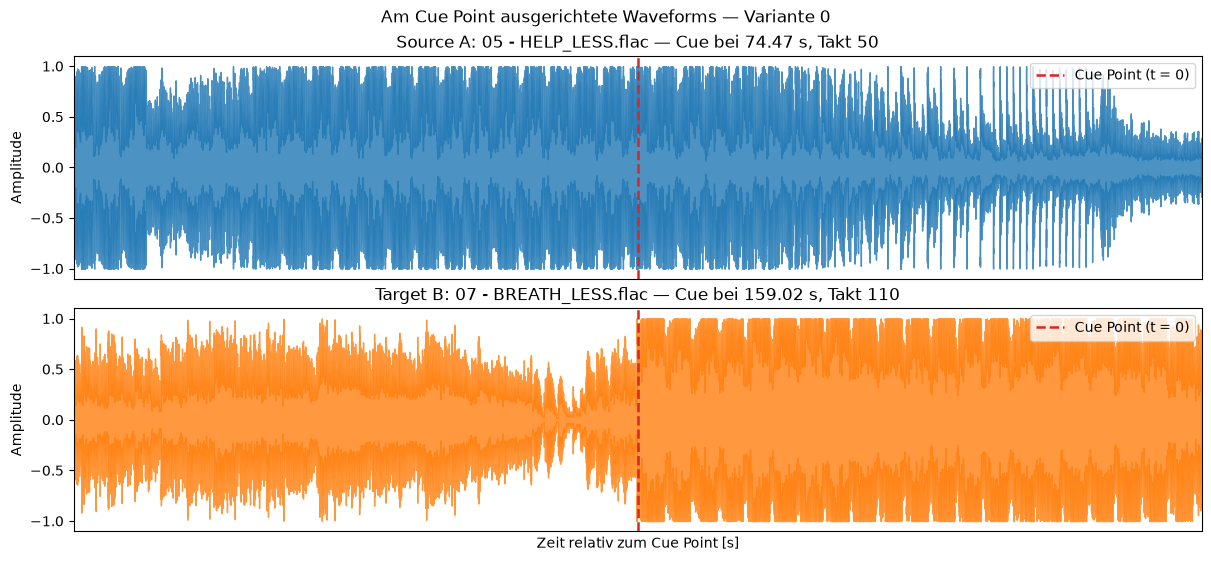

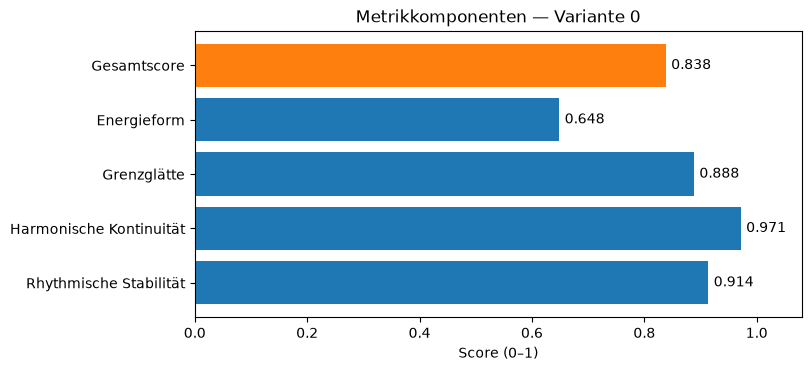

In [4]:
def resolve_track_path(track):
    """Löse einen Trackpfad aus dem Kandidaten relativ zum Projekt-Root auf."""
    path = Path(track["path"])
    return path if path.is_absolute() else PROJECT_ROOT / path

def load_cue_window(track, cutpoint, sample_rate, seconds_before, seconds_after):
    """Lade einen Mono-Ausschnitt und gib seinen Start relativ zum Cue Point zurück."""
    audio_path = resolve_track_path(track)
    if not audio_path.is_file():
        raise FileNotFoundError(f"Audio-Datei nicht gefunden: {audio_path}")

    cue_seconds = cutpoint["sample"] / sample_rate
    window_start = max(0.0, cue_seconds - seconds_before)
    duration = cue_seconds + seconds_after - window_start
    audio, _ = librosa.load(
        audio_path,
        sr=sample_rate,
        mono=True,
        offset=window_start,
        duration=duration,
    )
    return audio, window_start - cue_seconds, cue_seconds, audio_path

def plot_cue_points(index=0, seconds_before=8.0, seconds_after=8.0):
    """Richte Source- und Target-Waveform an ihren Cue Points bei t=0 aus."""
    if seconds_before <= 0 or seconds_after <= 0:
        raise ValueError("seconds_before und seconds_after müssen größer als 0 sein")

    variant = variants[index]
    candidate = candidates[variant["candidate_id"]]
    sample_rate = int(variant.get("sample_rate") or 44_100)
    rows = (
        ("Source A", "source_track", "source_cutpoint", "C0"),
        ("Target B", "target_track", "target_cutpoint", "C1"),
    )

    figure, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, constrained_layout=True)
    for axis, (label, track_key, cutpoint_key, color) in zip(axes, rows):
        cutpoint = candidate[cutpoint_key]
        audio, offset, cue_seconds, audio_path = load_cue_window(
            candidate[track_key],
            cutpoint,
            sample_rate,
            seconds_before,
            seconds_after,
        )
        librosa.display.waveshow(
            audio,
            sr=sample_rate,
            max_points=20_000,
            axis=None,
            offset=offset,
            color=color,
            alpha=0.8,
            ax=axis,
        )
        axis.axvline(0, color="C3", linestyle="--", linewidth=1.8, label="Cue Point (t = 0)")
        axis.set(
            xlim=(-seconds_before, seconds_after),
            ylabel="Amplitude",
            title=(
                f"{label}: {audio_path.name} — Cue bei {cue_seconds:.2f} s, "
                f"Takt {cutpoint['bar_index']}"
            ),
        )
        axis.grid(axis="x", alpha=0.2)
        axis.legend(loc="upper right")

    axes[-1].set_xlabel("Zeit relativ zum Cue Point [s]")
    figure.suptitle(f"Am Cue Point ausgerichtete Waveforms — Variante {index}")
    return figure

def plot_variant_metric_components(index):
    """Zeige Gesamtscore und Komponenten einer gerenderten Variante."""
    metric = metric_score_for(variants[index])
    if metric is None:
        print(f"Keine Render-Metrik für Variante {index} vorhanden.")
        return None

    components = metric.get("component_scores", {})
    keys = list(METRIC_LABELS)
    labels = ["Gesamtscore", *(METRIC_LABELS[key] for key in keys)]
    values = [metric["total_score"], *(components[key] for key in keys)]
    colors = ["C1", *("C0" for _ in keys)]

    figure, axis = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
    bars = axis.barh(labels, values, color=colors)
    axis.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=4)
    axis.set(xlim=(0, 1.08), xlabel="Score (0–1)", title=f"Metrikkomponenten — Variante {index}")
    axis.invert_yaxis()
    return figure

def play(index=0):
    """Spiele eine Variante über ihren Index aus der Liste oben ab."""
    variant = variants[index]
    candidate = candidates[variant["candidate_id"]]
    audio_path = BATCH_DIR / variant["output_file"]
    if not audio_path.is_file():
        raise FileNotFoundError(f"WAV-Datei nicht gefunden: {audio_path}")

    display(Markdown(
        f"### Variante {index}: Render-Rang {variant.get('transition_rank', '?')}, "
        f"Render-Score {display_score(variant, 'transition_score')}, "
        f"Cutpoint-Rang {variant.get('candidate_rank', '?')}, "
        f"Cutpoint-Score {display_score(variant, 'candidate_score')}, "
        f"`{variant['renderer']}`  \n"
        f"Kandidat `{variant['candidate_id']}`, "
        f"{candidate['transition_length_bars']} Takte / "
        f"{candidate['transition_length_beats']} Beats"
    ))
    cue_figure = plot_cue_points(index)
    display(cue_figure)
    plt.close(cue_figure)
    metric_figure = plot_variant_metric_components(index)
    if metric_figure is not None:
        display(metric_figure)
        plt.close(metric_figure)
    return Audio(filename=str(audio_path))

play(0)

### Variante 0: Render-Rang 1, Render-Score 0.838, Cutpoint-Rang 2, Cutpoint-Score 0.749, `equal_power`  
Kandidat `candidate-2801340071d831d4`, 4 Takte / 16 Beats

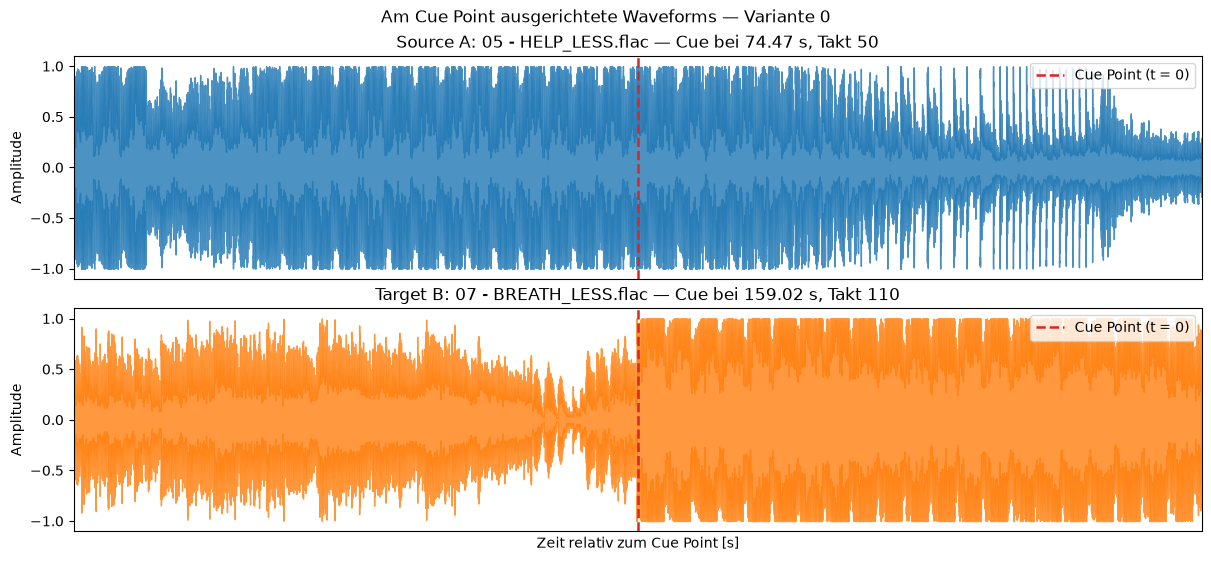

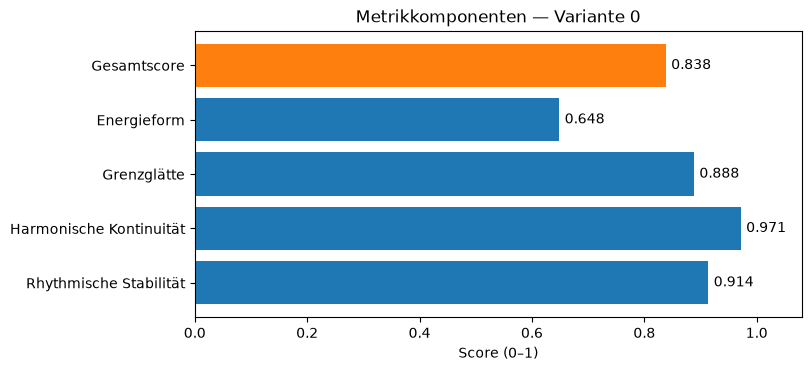

In [5]:
def play_renderer(renderer):
    """Spiele die erste Variante eines Renderers ab, z. B. 'equal_power'."""
    for index, variant in enumerate(variants):
        if variant["renderer"] == renderer:
            return play(index)
    raise ValueError(f"Renderer nicht im Batch: {renderer}")

# Direkter A/B-Vergleich zum ersten Lauf:
play_renderer("equal_power")

## Variante bewerten

`rate(...)` speichert oder aktualisiert eine Bewertung von 1 (schlecht) bis 5 (sehr gut) atomar in `ratings.json` neben dem Manifest. Fehler-Tags: `rhythm`, `phrasing`, `harmony`, `energy`, `loudness`, `vocals`, `artifacts`, `other`.

In [6]:
def rate(index, overall, issues=(), notes=""):
    """Bewerte eine angehörte Variante und speichere das Urteil dauerhaft."""
    variant = variants[index]
    saved = save_rating(
        BATCH_DIR,
        variant["candidate_id"],
        variant["renderer"],
        overall,
        issues=issues,
        notes=notes,
    )
    print(f"Gespeichert: Variante {index} = {saved['overall']}/5")
    return saved

def show_ratings():
    rows = rating_summary(BATCH_DIR)
    if not rows:
        print("Noch keine Bewertungen gespeichert.")
    for row in rows:
        print(
            f"{row['overall']}/5 | {row['renderer']} | {row['candidate_id']} | "
            f"{row['issues']} | {row['notes']}"
        )
    return rows

print("Fehler-Tags:", ", ".join(ISSUE_TAGS))
# Beispiel nach dem Anhören:
# rate(0, 2, issues=("phrasing", "vocals"), notes="Einstieg wirkt zu früh.")
show_ratings()

Fehler-Tags: rhythm, phrasing, harmony, energy, loudness, vocals, artifacts, other
Noch keine Bewertungen gespeichert.


[]

In [ ]:
play(1)

### Variante 1: Render-Rang 2, Render-Score 0.805, Cutpoint-Rang 1, Cutpoint-Score 0.751, `equal_power`  
Kandidat `candidate-5f8a2a500211a427`, 4 Takte / 16 Beats

In [ ]:
# Nach dem eigenen Hörurteil mit passenden Werten aktiv ausführen:
# rate(1, 2, issues=("energy",), notes="Der Energieverlauf wirkt unplausibel.")

## Hörnotizen

Beim Vergleich besonders auf Beat-Stabilität, wahrgenommene Lautheit im Übergang, klangliche Kontinuität, Energieverlauf und mögliche Vocal-Clashes achten. Auffälligkeiten mit Variantenindex, Kandidaten-ID und Renderer in `docs/Bemerkungen.md` festhalten.